# Prediction, projection and grouping: three questions for one dataset

Can the same measurements support a prediction, a projection and a grouping without making those outputs equivalent?

Winter 2026.


# Prediction, projection and grouping
Before running, name the output of each method. Data are synthetic. The supplied split is fixed; do not choose model settings from test outcomes.

In [1]:
import numpy as np
from demo import make_data, fit_line, rmse, fit_standardizer, fit_pca, fit_two_centers, run
from IPython.display import SVG, display
x, y, train, test = make_data()
print("Feature table:", x.shape, "training:", len(train), "test:", len(test))
assert not set(train) & set(test)
coefficients = fit_line(x[train, 0], y[train])
predicted_test = coefficients[0] + coefficients[1] * x[test, 0]
print("Coefficients [mV, mV/mm]:", coefficients)
print("Test RMSE (mV):", rmse(y[test], predicted_test))

Feature table: (120, 2) training: 90 test: 30
Coefficients [mV, mV/mm]: [5.36555175 1.48594453]
Test RMSE (mV): 1.5361877560379458


Interpret the slope unit and one residual. The following baseline uses the training mean, even when evaluating test rows. Predict whether it will do better or worse here, then run and display both original figures.

Constant baseline test RMSE (mV): 4.683291420083419


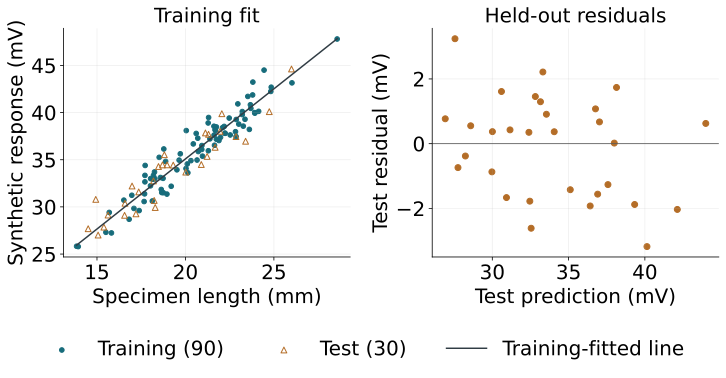

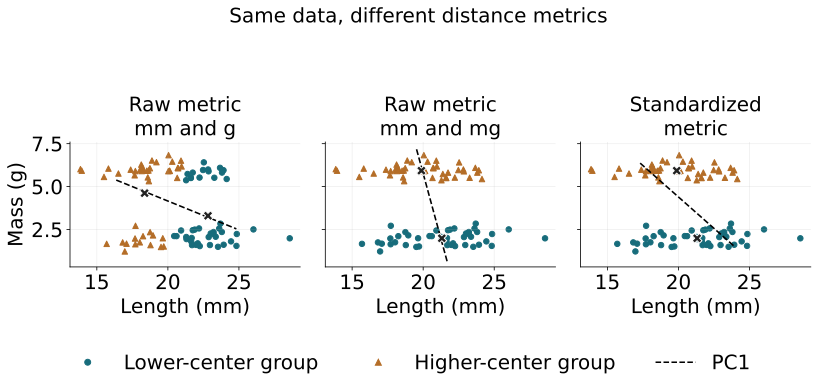

In [2]:
baseline = np.full(len(test), y[train].mean())
print("Constant baseline test RMSE (mV):", rmse(y[test], baseline))
report = run()
display(SVG(filename="regression-and-residuals.svg"))
display(SVG(filename="scale-projection-groups.svg"))

Trace the projection shapes. The mean and scale below come only from training rows. Compare full two-component reconstruction with a one-component reconstruction; explain which result should have zero error up to rounding.

In [3]:
mean, scale = fit_standardizer(x[train])
z_train = (x[train] - mean) / scale
z_test = (x[test] - mean) / scale
pca = fit_pca(z_train)
centered = z_test - pca["center"]
scores = centered @ pca["components"].T
full = scores @ pca["components"] + pca["center"]
one = scores[:, :1] @ pca["components"][:1] + pca["center"]
print("Scores:", scores.shape)
print("Full reconstruction maximum error:", np.max(np.abs(full - z_test)))
print("One-component mean squared feature error:", np.mean((one - z_test)**2))

Scores: (30, 2)
Full reconstruction maximum error: 2.220446049250313e-16
One-component mean squared feature error: 0.5366805098014595


Modify a unit, not an observation: convert grams to milligrams. Predict what standardization will preserve. Then compare group membership through same-group pairs, so arbitrary zero/one names do not create false disagreement.

In [4]:
converted = x[train] * np.array([1.0, 1000.0])
converted_mean, converted_scale = fit_standardizer(converted)
z_converted = (converted - converted_mean) / converted_scale
assert np.allclose(z_train, z_converted)
group_a = fit_two_centers(z_train)["labels"]
group_b = fit_two_centers(z_converted)["labels"]
same_a = group_a[:, None] == group_a[None, :]
same_b = group_b[:, None] == group_b[None, :]
print("Standardized membership preserved:", np.array_equal(same_a, same_b))

Standardized membership preserved: True


Change one named feature scaling in a new exploratory copy and predict the raw geometry before running. Keep the original test comparison unchanged. Restart and run all cells; write separate prediction, projection and grouping conclusions with one limitation each.